# Borjas, *Labor Economics* (9th ed.), Chapter 2: Data behind the examples

Inventory of the empirical examples in the labor supply chapter, the datasets behind them, and how to get the data.

Status legend: ✅ transcribed from the book and stored in `odata/borjas_ch02/`; ⬇️ downloaded; 🔗 not downloaded (restricted, needs registration, or blocked for scripts), links given.

| # | Example (book) | Data | Status |
|---|---|---|---|
| 1 | Table 2-1, LFPR of men 1900–2019 | Census / BLS | ✅ |
| 2 | Table 2-2, LFPR of women by marital status | Census / BLS | ✅ |
| 3 | Fig 2-1, weekly hours 1900–2013 | Jones (1963); BLS CES | ⬇️ post-1939 (FRED), 🔗 pre-1939 |
| 4 | Table 2-3, labor supply by group, 2021 | CPS-ASEC 2021 | ✅ table, 🔗 microdata |
| 5 | Figs 2-22, 2-23, life cycle, 2017 | CPS-ASEC 2017 | 🔗 |
| 6 | Data Explorer: fertility and labor supply | IPUMS CPS-ASEC 1968– | 🔗 |
| 7 | Table 2-4, EITC (Eissa–Liebman) | CPS 1984–1990 | ✅ table, 🔗 microdata |
| 8 | Table 2-5, disability benefits (Gruber) | Canadian LFS | ✅ table, 🔗 microdata |
| 9 | Lottery winners | Kaplan; Imbens et al.; Cesarini et al. | 🔗 |
| 10 | NYC taxi drivers, 1996 fare change | Ashenfelter–Doran–Schaller | 🔗 |
| 11 | Sleep and the price of time | Time Use Study 1975–76 | 🔗 |
| 12 | Time use 2013, paid work vs housework | ATUS 2013 | 🔗 |
| 13 | Welfare experiments (MFIP) | MDRC / ICPSR 38093 | 🔗 |
| 14 | Gaming the EITC (Chetty–Friedman–Saez) | IRS records | 🔗 replication package |

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, ".")
import common  # shared plot style
D = Path("../odata/borjas_ch02")

## 1. Table 2-1: Labor force participation rates of men, 1900–2019 (✅)

Sources: Census, *Historical Statistics of the United States* (1975); *Statistical Abstract*; BLS civilian LFPR by age, sex, race. Post-1948 updates: BLS series LNS11300001 (men) on [FRED](https://fred.stlouisfed.org/series/LNS11300001).

,year,all_men,men_25_44,men_45_64,men_65_plus
9,2000,74.8,93.1,78.3,17.5
10,2010,71.2,90.6,78.4,22.1
11,2019,69.2,90.0,79.5,24.7


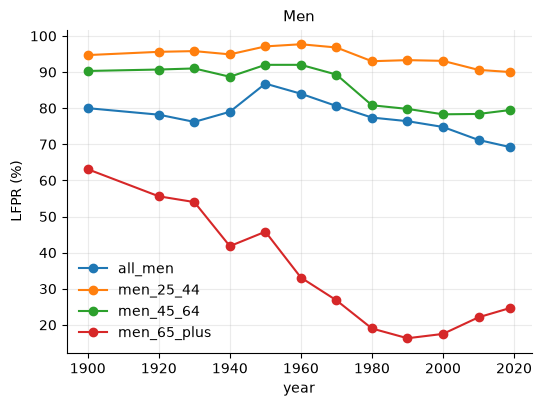

In [2]:
men = pd.read_csv(D / "table_2_1_lfpr_men.csv")
ax = men.set_index("year").plot(marker="o")
ax.set_ylabel("LFPR (%)"); ax.set_title("Men"); men.tail(3)

## 2. Table 2-2: Labor force participation rates of women, 1900–2019 (✅)

Sources: Census *Historical Statistics* (1975, p. 133); *Statistical Abstract* 2011, Table 596; BLS employment status by marital status and gender, 2019. Updates: FRED [LNS11300002](https://fred.stlouisfed.org/series/LNS11300002). Note: 1920 is missing in the book's table.

,year,all_women,single,married,widowed_divorced_separated
9,2000,59.9,68.9,61.1,49.0
10,2010,58.6,63.3,61.0,48.8
11,2019,57.4,65.0,58.6,45.9


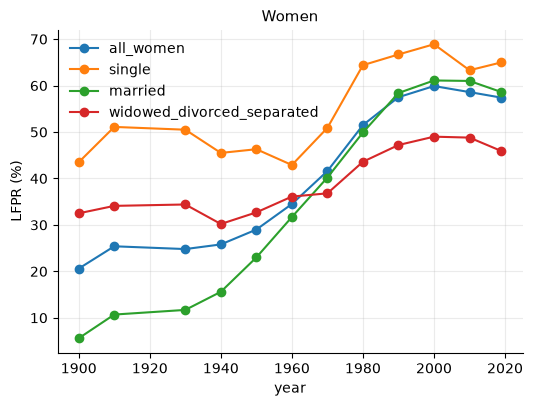

In [3]:
women = pd.read_csv(D / "table_2_2_lfpr_women.csv")
ax = women.set_index("year").plot(marker="o")
ax.set_ylabel("LFPR (%)"); ax.set_title("Women"); women.tail(3)

## 3. Figure 2-1: Average weekly hours, 1900–2013 (⬇️ partly)

* Post-war: BLS Current Employment Statistics, Table B-7 (production/nonsupervisory workers). Downloaded from FRED: `AWHMAN` (manufacturing, monthly from 1939) and `AWHNONAG` (total private, 1964–).
* Pre-1947: manufacturing only, from Jones, "New Estimates of Hours of Work per Week and Hourly Earnings, 1900–1957", *REStat* 45 (1963): 374–385 (print only, no machine-readable version found). Related: Census, *Historical Statistics of the United States*, Colonial Times to 1970, series D765 (hours in manufacturing); also [EH.net hours of work](https://eh.net/encyclopedia/hours-of-work-in-u-s-history/).

,AWHMAN,AWHNONAG
count,1054.0,754.0
mean,40.8,34.8
std,1.2,1.4
min,37.0,33.0
25%,40.3,33.8
50%,40.7,34.4
75%,41.3,35.6
max,45.7,38.8


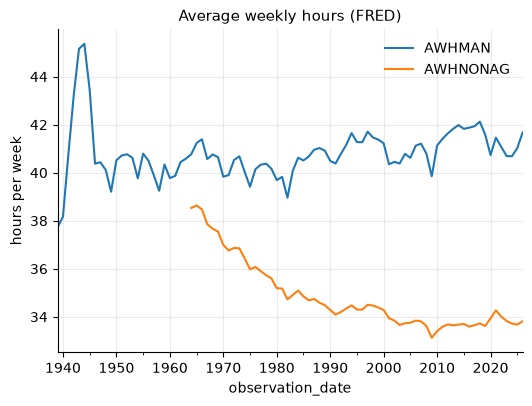

In [4]:
h = {s: pd.read_csv(D / "fred" / f"{s}.csv", parse_dates=["observation_date"], index_col=0)[s] for s in ["AWHMAN", "AWHNONAG"]}
ax = pd.DataFrame(h).resample("YS").mean().plot()
ax.set_ylabel("hours per week"); ax.set_title("Average weekly hours (FRED)")
pd.DataFrame(h).dropna(how="all").describe().round(1)

## 4. Table 2-3: Labor supply in the US, 2021, ages 25–64 (✅ table, 🔗 microdata)

Source: CPS-ASEC, March 2021. Hours are computed among workers; part-time = fewer than 30 hours per week.
Microdata: [IPUMS-CPS](https://cps.ipums.org/cps/) (free registration) or Census [CPS ASEC 2021 files](https://www.census.gov/data/datasets/time-series/demo/cps/cps-asec.2021.html). The Census server rejected scripted downloads, so open them in a browser.

,group,category,lfpr_men,lfpr_women,hours_men,hours_women,parttime_men,parttime_women
0,All,All persons,82.3,71.5,2084,1889,4.6,12.0
1,Education,Less than 12 years,69.7,44.0,1928,1662,5.6,17.4
2,Education,12 years,77.0,61.1,2017,1797,5.2,14.5
3,Education,13-15 years,81.8,72.2,2080,1829,4.9,13.1
4,Education,16 years or more,90.0,81.2,2154,1973,3.7,9.9
5,Age,25-34,85.3,76.2,2021,1851,4.7,11.4
6,Age,35-44,88.1,74.3,2109,1888,3.5,11.8
7,Age,45-54,85.2,75.5,2133,1926,3.7,11.0
8,Age,55-64,70.1,60.2,2076,1894,6.7,14.0
9,Race,White,83.0,73.2,2127,1896,4.4,12.6


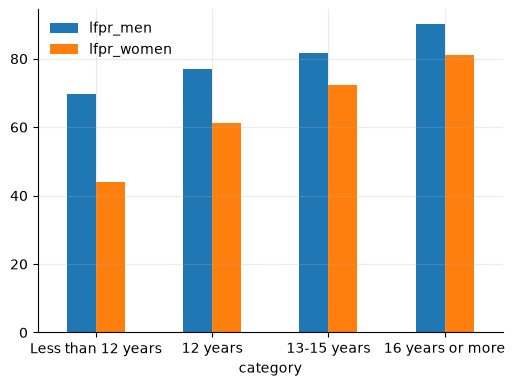

In [5]:
t3 = pd.read_csv(D / "table_2_3_labor_supply_2021.csv")
t3[t3.group == "Education"].set_index("category")[["lfpr_men", "lfpr_women"]].plot.bar(rot=0)
t3

## 5. Figures 2-22 and 2-23: Participation and hours over the life cycle, 2017 (🔗)

Source: CPS-ASEC 2017. Not transcribable (figures only).
* Census microdata directory: <https://www2.census.gov/programs-surveys/cps/datasets/2017/march/> (files `asecpub17csv.zip`; the directory listing is public, scripted file requests were rejected, download in a browser).
* IPUMS-CPS extract (easiest): variables `year, age, sex, labforce, uhrsworkly/wkswork1, asecwt`, sample 2017 ASEC.
* Partial substitute: BLS LFPR by age, [CPS table 3.3](https://www.bls.gov/cps/cpsaat03.htm) (all years), or FRED age-group series.

## 6. Data Explorer: Fertility and labor supply (🔗)

From the book (p. 79): IPUMS-CPS, Annual Social and Economic Supplement, 1968–present, <https://cps.ipums.org/cps/>.

| Variable | IPUMS name |
|---|---|
| Sex | `sex` |
| Age | `age` |
| Survey year | `year` |
| Labor force status | `labforce` |
| Own children under 5 | `nchlt5` |
| Sampling weight | `asecwt` |

Sample: civilians aged 20–50 with `labforce != 0`. Created variables: in labor force (`labforce == 2`), has child under 5 (`nchlt5 >= 1`). Compute weighted LFPR by year, sex and presence of young children. Requires a free IPUMS account; extract cannot be scripted without an API key (the IPUMS API is available via `ipumspy`).

## 7. Table 2-4: The EITC and participation (✅ table, 🔗 microdata)

Eissa and Liebman, "Labor Supply Response to the Earned Income Tax Credit", *QJE* 111 (1996). Data: March CPS around the 1986 Tax Reform Act (exact years not verified). Microdata via IPUMS-CPS (annual March files).

In [6]:
t4 = pd.read_csv(D / "table_2_4_eitc.csv").set_index("group")
t4["change"] = t4.after_pct - t4.before_pct
print("Difference-in-differences:", round(t4.loc["treatment", "change"] - t4.loc["control", "change"], 1))
t4

Difference-in-differences: 2.4


,description,before_pct,after_pct,change
group,,,,
treatment,Unmarried women with children (EITC eligible),72.9,75.3,2.4
control,Unmarried women without children (not eligible),95.2,95.2,0.0


## 8. Table 2-5: Disability benefits in Canada (✅ table, 🔗 microdata)

Gruber, "Disability Insurance Benefits and Labor Supply", *JPE* 108 (2000). Data: Canadian Labour Force Survey around 1986–87 (Statistics Canada; access via licensed public-use microdata or data centres; see <https://www.statcan.gc.ca/en/survey/household/3701>), plus CPP/QPP benefit schedules.

In [7]:
t5 = pd.read_csv(D / "table_2_5_disability_canada.csv")
t5["change"] = t5.after - t5.before
emp = t5[t5.measure.str.startswith("pct")].set_index("group").change
print("Difference-in-differences (CPP vs QPP):", round(emp["CPP (treatment)"] - emp["QPP (control)"], 1))
t5

Difference-in-differences (CPP vs QPP): 2.7


,measure,group,before,after,change
0,annual_benefit_cad,CPP (rest of Canada),5134.0,7776.0,2642.0
1,annual_benefit_cad,QPP (Quebec),6876.0,7852.0,976.0
2,pct_men_45_59_not_employed,CPP (treatment),20.0,21.7,1.7
3,pct_men_45_59_not_employed,QPP (control),25.6,24.6,-1.0


## 9. Lottery winners and income effects (🔗)

* Kaplan (1987) early survey of ~1,000 winners (see the book's endnote 22 for the reference), not publicly available.
* Imbens, Rubin, Sacerdote, *AER* 91 (2001): 778–794. Survey of Massachusetts lottery players plus SSA earnings. No official replication package found. A reanalysis with the data (`lottery.RData`) is in Yiqing Xu's tutorial: <https://yiqingxu.org/tutorials/lalonde/05-IRS.html>.
* Cesarini, Lindqvist, Notowidigdo, Östling, *AER* 107 (2017). Replication code (no data): [openICPSR 116181](https://www.openicpsr.org/openicpsr/project/116181). Swedish registers are restricted. Paper: [NBER w21762](https://www.nber.org/papers/w21762).

## 10. NYC taxi drivers and the 1996 fare change (🔗)

The −0.19 elasticity matches the study of Ashenfelter, Doran, and Schaller, "A Shred of Credible Evidence on the Long Run Elasticity of Labor Supply", *Economica* (2010), [NBER w15746](https://www.nber.org/papers/w15746), which uses the March 1996 and May 2004 fare increases (revenue per mile up by about 19 percent; miles driven down by about 4 percent; elasticity about −0.2). Their data are TLC trip-sheet records, not public. The book's exact source is not named in the extracted text, so check its endnote. Modern public NYC taxi trip data (2009+) are at <https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page> but do not cover 1996.

## 11. Sleep and the allocation of time (🔗)

Biddle and Hamermesh, *JPE* 98 (1990): 922–943 ([NBER w2988](https://www.nber.org/papers/w2988)). Likely data: [Time Use in Economic and Social Accounts, 1975–1976 (ICPSR 7580)](https://www.icpsr.umich.edu/web/ICPSR/studies/7580) (free at ICPSR member institutions; the exact study used was not verified), plus the 1981 Time Use Longitudinal Panel Study. Their cross-country data are aggregates from published time-use studies.

## 12. Time allocation in 2013 (🔗)

Hours of paid work vs housework and child care (33.8 vs 11.8 for men, 23.9 vs 24.3 for women): American Time Use Survey, 2013. Data: <https://www.bls.gov/tus/data/datafiles-2013.htm> (BLS rejected scripted downloads, so use a browser). Tables: <https://www.bls.gov/tus/tables.htm>.

## 13. Welfare experiments (🔗)

Minnesota Family Investment Program (random assignment of >14,000 families). Public information: [MDRC project page](https://www.mdrc.org/project/minnesota-family-investment-program). Data: [ICPSR 38093](https://www.icpsr.umich.edu/web/ICPSR/studies/38093), restricted use (agreement needed). The negative-income-tax experiments (Seattle/Denver SIME/DIME) are archived at ICPSR as well.

## 14. Gaming the EITC (🔗)

Chetty, Friedman, Saez, *AER* 103 (2013): 2683–2721 ([NBER w18232](https://www.nber.org/papers/w18232)). Underlying IRS tax records are restricted. Replication package: [openICPSR 112681](https://www.openicpsr.org/openicpsr/project/112681). Aggregate tables may also be on [Opportunity Insights](https://opportunityinsights.org/).

---
*Links marked 🔗 were located by web search. Where the site blocked scripted requests (ICPSR, BLS, Census files) availability was not verified by download.*